<a href="https://colab.research.google.com/github/Shravani408/Netflix-Data-Cleaning-Using-Python-Description-/blob/Shravani408-patch-1/Netflix_Trend_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

file_path = '/content/netflix_cleaned.csv'

# Check if the file exists before reading
if os.path.exists(file_path):
    try:
        # Try loading with default UTF-8 first
        df = pd.read_csv(file_path)
        print("Dataset loaded successfully with UTF-8 encoding!")
        display(df.head())
    except UnicodeDecodeError:
        try:
            # Try loading with latin-1 encoding if UTF-8 fails
            df = pd.read_csv(file_path, encoding='latin-1')
            print("Dataset loaded successfully with latin-1 encoding!")
            display(df.head())
        except Exception as e:
            print(f"An error occurred while loading the dataset: {e}")
else:
    print(f"Error: '{file_path}' not found. Please upload the file to your Colab workspace and run this cell again.")

Dataset loaded successfully with latin-1 encoding!


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (8790, 10)

Dataset Columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [7]:
# Check missing values
print("Missing Release Years:",
      df['release_year'].isnull().sum())

# Convert release_year into numeric format
df['release_year'] = pd.to_numeric(
    df['release_year'], errors='coerce'
)

# Remove rows with missing release year
df = df.dropna(subset=['release_year'])

# Convert year into integer
df['release_year'] = df['release_year'].astype(int)

# Sort data by release year
df = df.sort_values(by='release_year')

df[['title', 'type', 'release_year']].head(10)

Missing Release Years: 0


,title,type,release_year
421,Pioneers: First Women Filmmakers*,TV Show,1925
6037,The Battle of Midway,Movie,1942
5698,Prelude to War,Movie,1942
6422,Undercover: How to Operate Behind Enemy Lines,Movie,1943
6510,WWII: Report from the Aleutians,Movie,1943
6491,Why We Fight: The Battle of Russia,Movie,1943
6406,Tunisian Victory,Movie,1944
6218,The Memphis Belle: A Story of a\nFlying Fortress,Movie,1944
6230,The Negro Soldier,Movie,1944
5545,Nazi Concentration Camps,Movie,1945


In [8]:
yearly_content = df.groupby(
    'release_year'
).size().reset_index(name='total_content')

print(yearly_content.tail(15))

    release_year  total_content
59          2007             88
60          2008            135
61          2009            152
62          2010            192
63          2011            185
64          2012            236
65          2013            286
66          2014            352
67          2015            555
68          2016            901
69          2017           1030
70          2018           1146
71          2019           1030
72          2020            953
73          2021            592


In [9]:
yearly_type = df.groupby(
    ['release_year', 'type']
).size().unstack(fill_value=0)

print(yearly_type.tail(15))

type          Movie  TV Show
release_year                
2007             74       14
2008            113       22
2009            118       34
2010            153       39
2011            145       40
2012            173       63
2013            225       61
2014            264       88
2015            396      159
2016            658      243
2017            765      265
2018            767      379
2019            633      397
2020            517      436
2021            277      315


In [11]:
# Calculate year-on-year content growth
yearly_content['growth'] = yearly_content[
    'total_content'
].diff()

# Calculate growth percentage
yearly_content['growth_percentage'] = (
    yearly_content['total_content'].pct_change() * 100
)

print(yearly_content.tail(15))

    release_year  total_content  growth  growth_percentage
59          2007             88    -8.0          -8.333333
60          2008            135    47.0          53.409091
61          2009            152    17.0          12.592593
62          2010            192    40.0          26.315789
63          2011            185    -7.0          -3.645833
64          2012            236    51.0          27.567568
65          2013            286    50.0          21.186441
66          2014            352    66.0          23.076923
67          2015            555   203.0          57.670455
68          2016            901   346.0          62.342342
69          2017           1030   129.0          14.317425
70          2018           1146   116.0          11.262136
71          2019           1030  -116.0         -10.122164
72          2020            953   -77.0          -7.475728
73          2021            592  -361.0         -37.880378


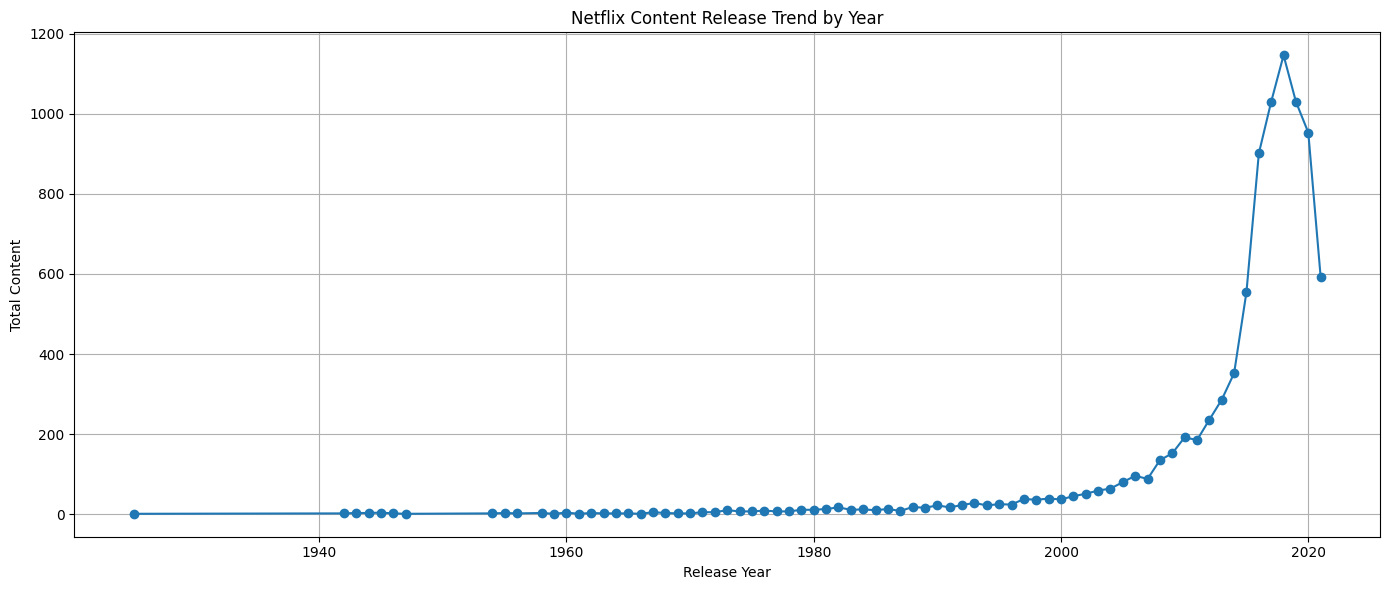

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_content['release_year'],
    yearly_content['total_content'],
    marker='o'
)

plt.title('Netflix Content Release Trend by Year')
plt.xlabel('Release Year')
plt.ylabel('Total Content')
plt.grid(True)

plt.tight_layout()
plt.show()

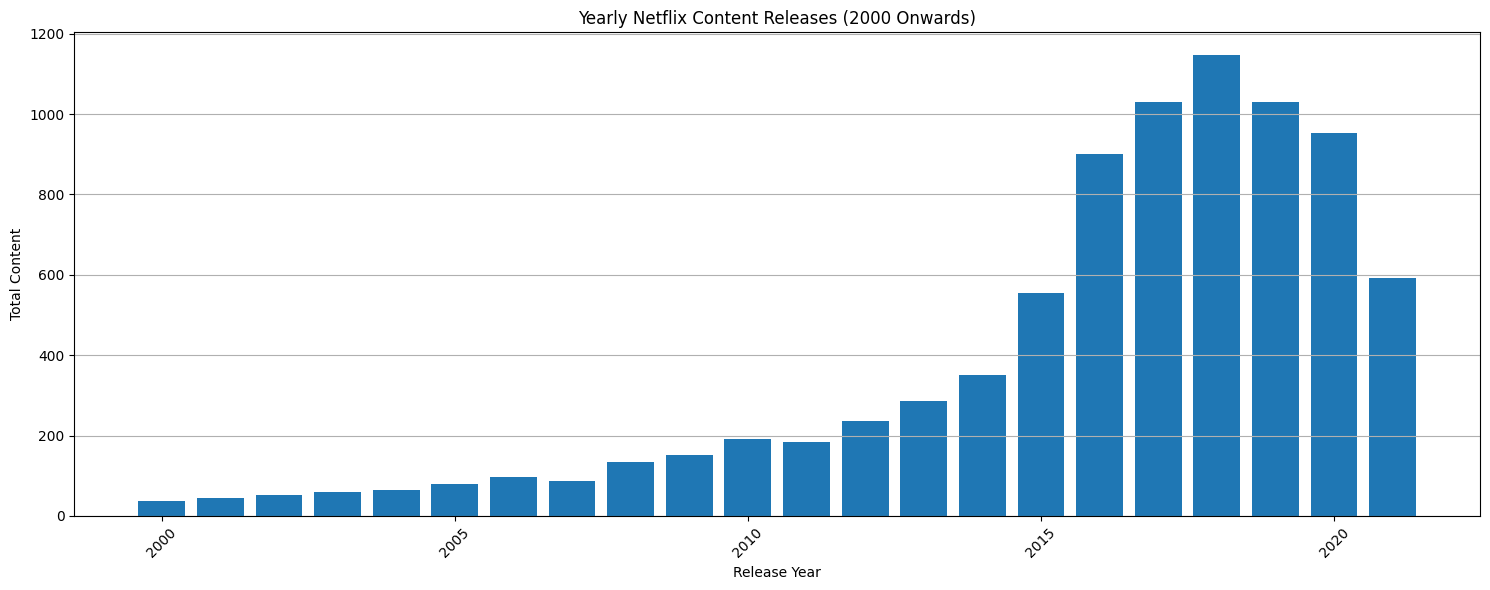

In [13]:
recent_years = yearly_content[
    yearly_content['release_year'] >= 2000
]

plt.figure(figsize=(15, 6))

plt.bar(
    recent_years['release_year'],
    recent_years['total_content']
)

plt.title('Yearly Netflix Content Releases (2000 Onwards)')
plt.xlabel('Release Year')
plt.ylabel('Total Content')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

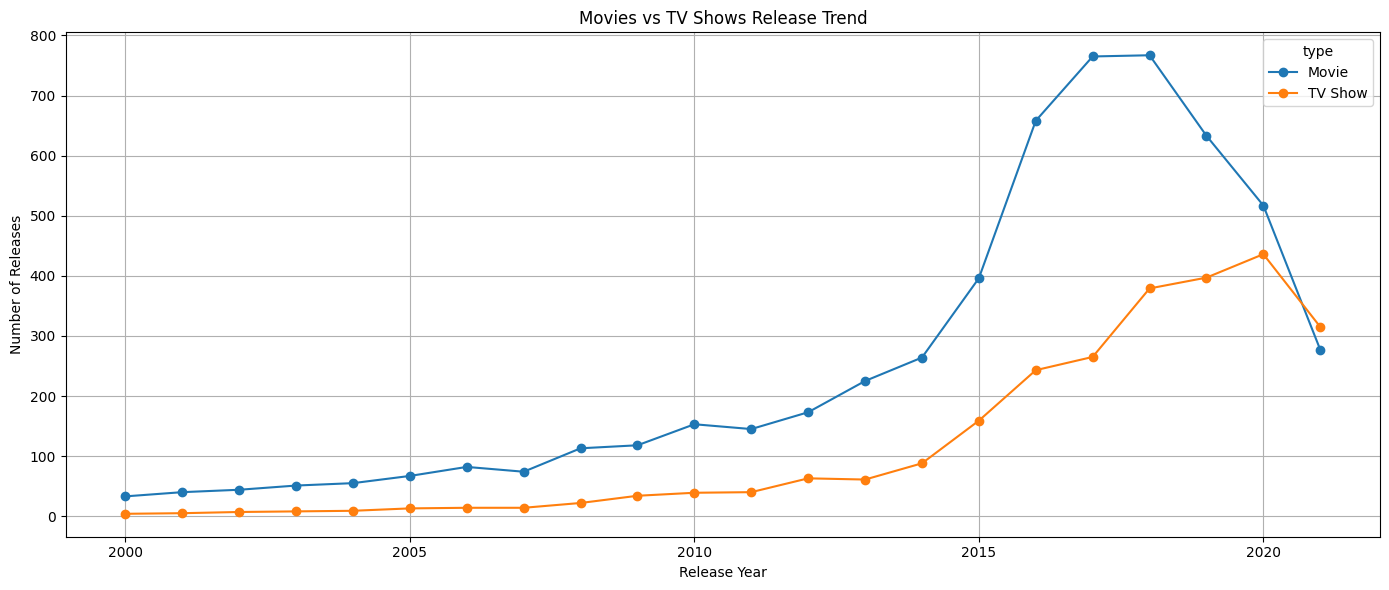

In [14]:
yearly_type_recent = yearly_type[
    yearly_type.index >= 2000
]

yearly_type_recent.plot(
    kind='line',
    figsize=(14, 6),
    marker='o'
)

plt.title('Movies vs TV Shows Release Trend')
plt.xlabel('Release Year')
plt.ylabel('Number of Releases')
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
highest_year = yearly_content.loc[
    yearly_content['total_content'].idxmax()
]

print("Year with Highest Content Release:",
      highest_year['release_year'])

print("Total Content Released:",
      highest_year['total_content'])

Year with Highest Content Release: 2018.0
Total Content Released: 1146.0


In [16]:
yearly_content.to_csv(
    'Netflix_Yearly_Trend_Analysis.csv',
    index=False
)

yearly_type.to_csv(
    'Netflix_Movies_TVShows_Trend.csv'
)

print("Analysis CSV files saved successfully!")

Analysis CSV files saved successfully!


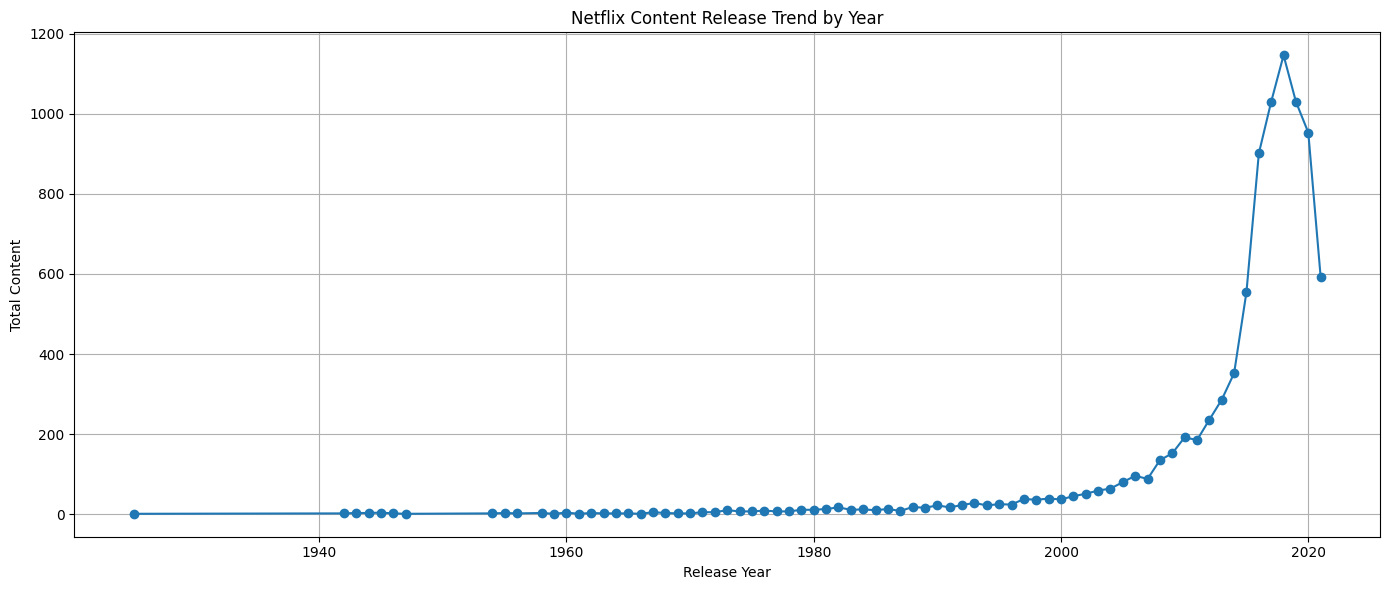

In [17]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_content['release_year'],
    yearly_content['total_content'],
    marker='o'
)

plt.title('Netflix Content Release Trend by Year')
plt.xlabel('Release Year')
plt.ylabel('Total Content')
plt.grid(True)

plt.tight_layout()
plt.savefig('Netflix_Yearly_Trend.png', dpi=300)
plt.show()